In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import keras_tuner as kt

import warnings
warnings.filterwarnings("ignore")

In [4]:
# Load dataset
df = pd.read_csv("Churn Modeling.csv")
print(df.shape)
df.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
# Data info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [6]:
# Columns name
print("\nColumn Names")
print(df.columns.tolist())


Column Names
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [7]:
# checking missing values

print("Missing values;")
print(df.isnull().sum())

Missing values;
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [8]:
# Checking duplicate values

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
# Statistical summary
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [10]:
# categorical variables
df.describe(include="object")

,Surname,Geography,Gender
count,10000,10000,10000
unique,2932,3,2
top,Smith,France,Male
freq,32,5014,5457


In [11]:
# target variable fixed

print(df["Exited"].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64


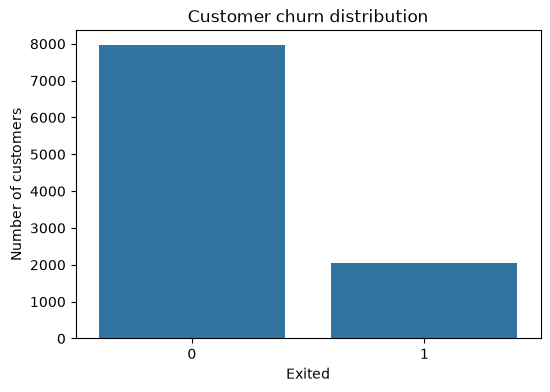

In [12]:
# Visualising target variable

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Exited")
plt.title("Customer churn distribution")
plt.xlabel("Exited")
plt.ylabel("Number of customers")
plt.show()

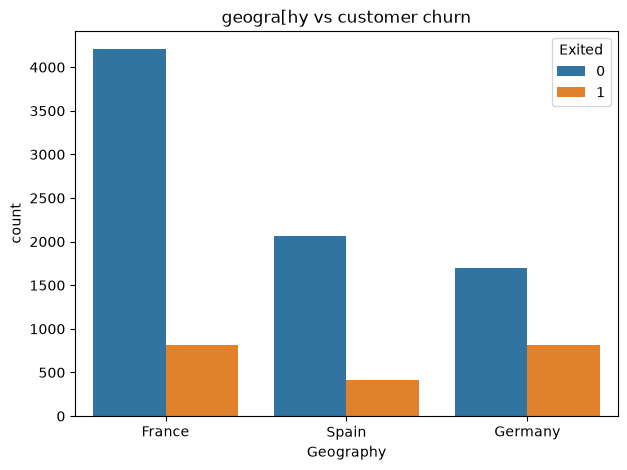

In [13]:
# EDA
# geography vs churn

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Geography", hue="Exited")
plt.title("geogra[hy vs customer churn")
plt.show()

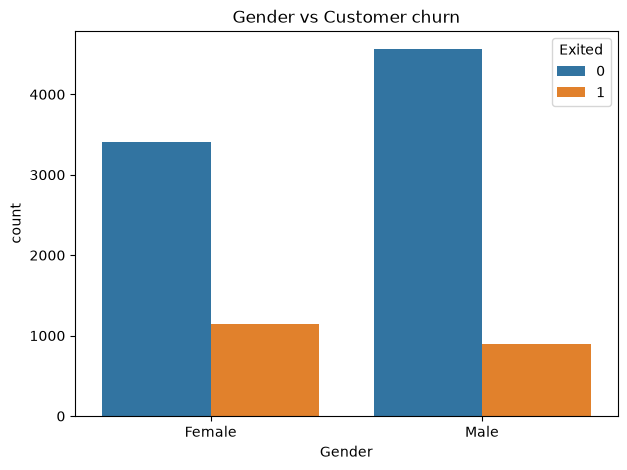

In [14]:
# Gender vs churn

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Gender", hue="Exited")
plt.title("Gender vs Customer churn")
plt.show()

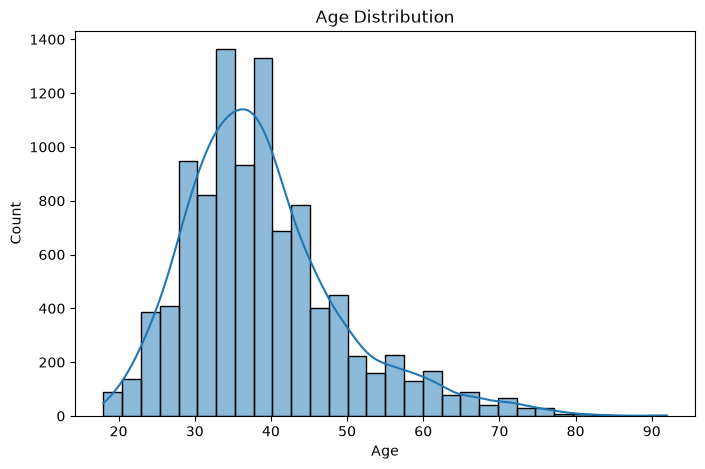

In [15]:
# age distribution

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Age", bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

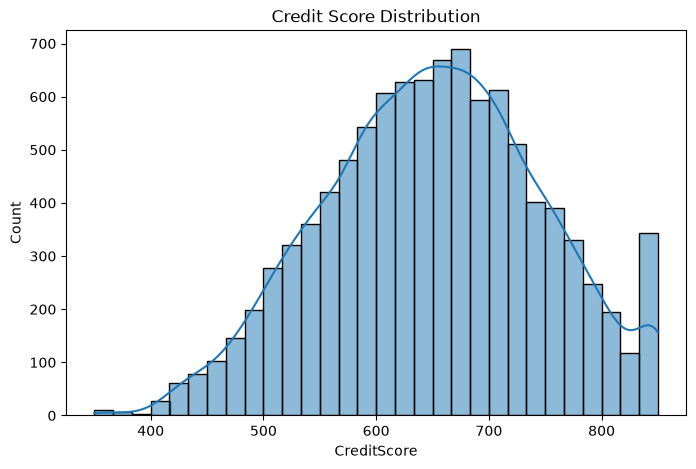

In [16]:
# Credit Score Distribution

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="CreditScore", bins=30, kde=True)
plt.title("Credit Score Distribution")
plt.show()

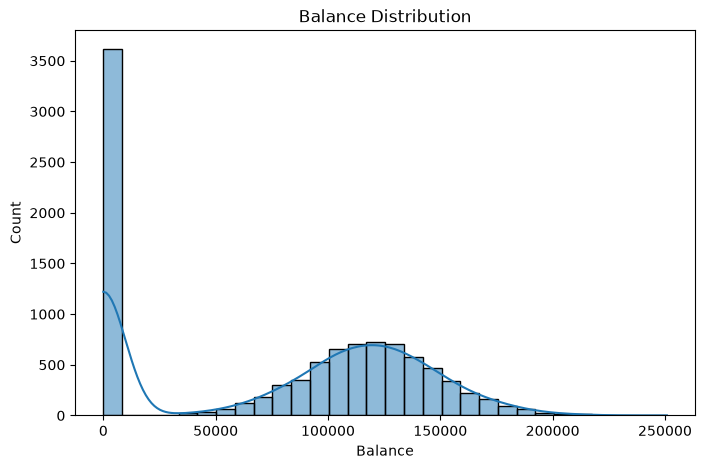

In [17]:
# Balance distribution

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Balance", bins=30, kde=True)
plt.title("Balance Distribution")
plt.show()

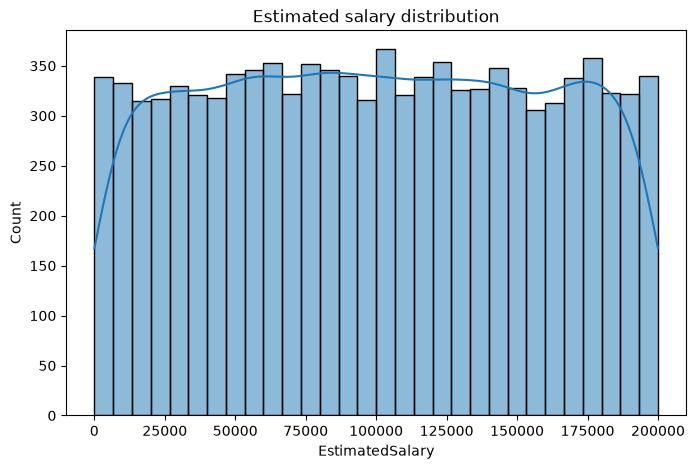

In [18]:
# Estimated salary distribution

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="EstimatedSalary", bins=30, kde=True)
plt.title("Estimated salary distribution")
plt.show()

In [19]:
# numeric variables 

numeric_columns = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
print(numeric_columns)

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']


In [20]:
# Checking skewness

skewness = df[numeric_columns].skew()
print("Skewness of numeric variables:", skewness)

Skewness of numeric variables: CreditScore       -0.071607
Age                1.011320
Tenure             0.010991
Balance           -0.141109
NumOfProducts      0.745568
EstimatedSalary    0.002085
dtype: float64


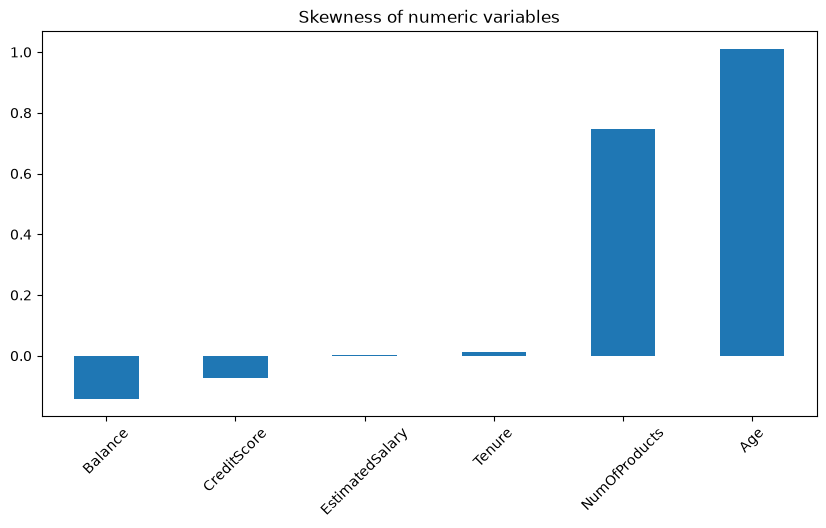

In [21]:
# Visualising skewness
plt.figure(figsize=(10,5))
skewness.sort_values().plot(kind="bar")
plt.title("Skewness of numeric variables")
plt.xticks(rotation=45)
plt.show()

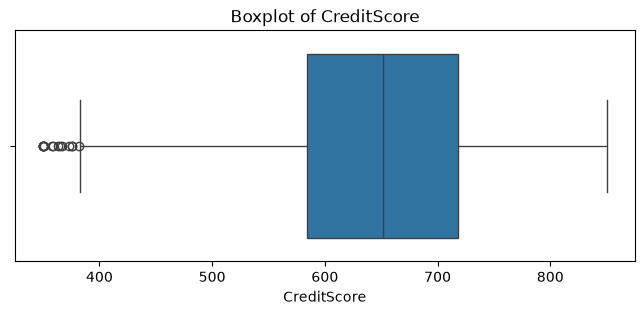

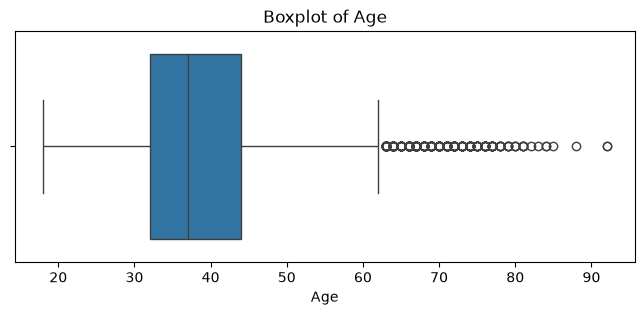

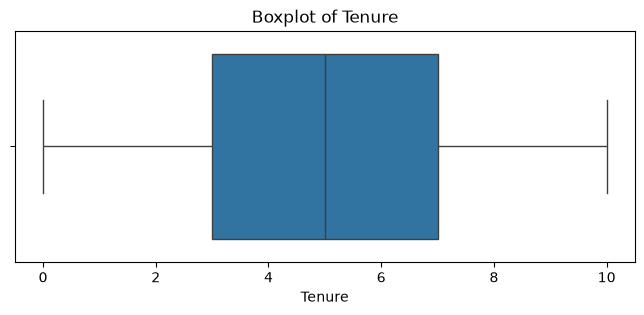

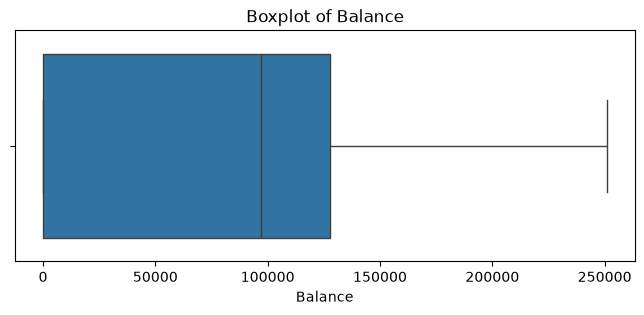

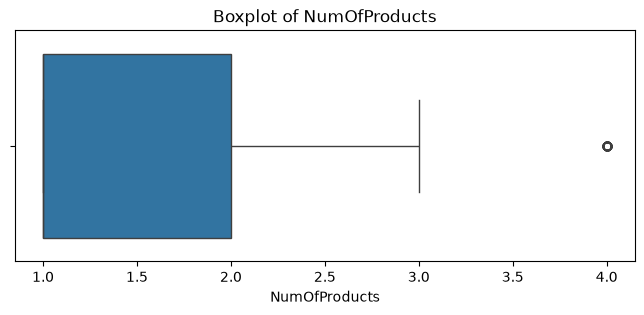

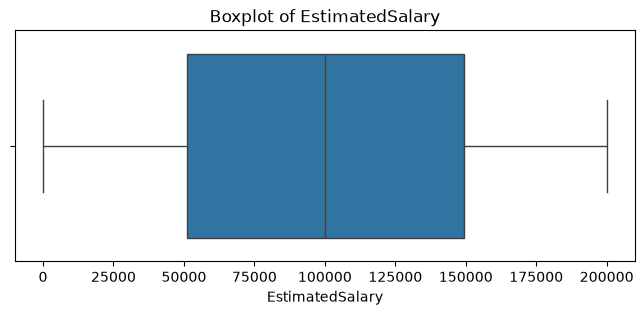

In [22]:
# Outlier detection

for column in numeric_columns:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

In [23]:
# treating outliers using IQR
def cap_outliers(data, columns):
    data = data.copy()
    for column in columns:
        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)

        IQR = Q3-Q1
        lower_limit = Q1 -1.5*IQR
        upper_limit = Q1 +1.5*IQR

        data[column] = data[column].clip(lower_limit, upper_limit)
    return data

df = cap_outliers(df, numeric_columns)
print("Outliers capped successfully")

Outliers capped successfully


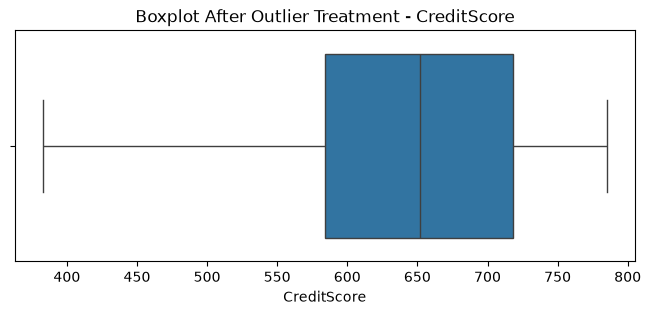

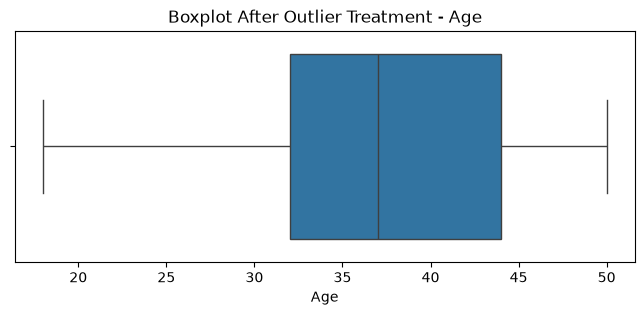

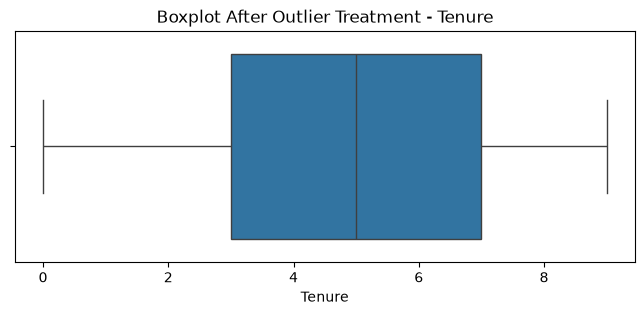

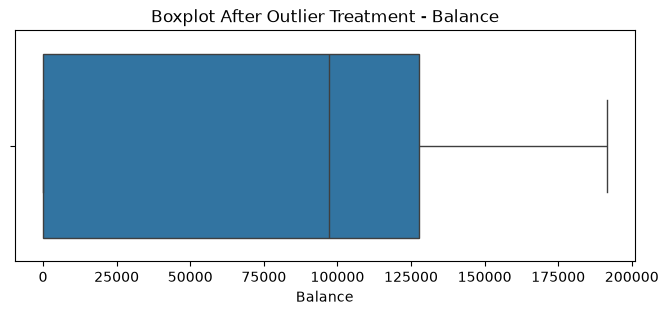

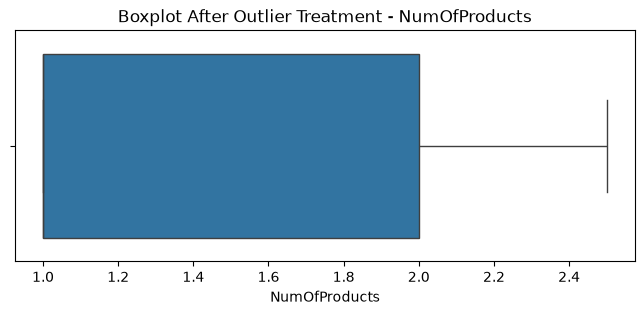

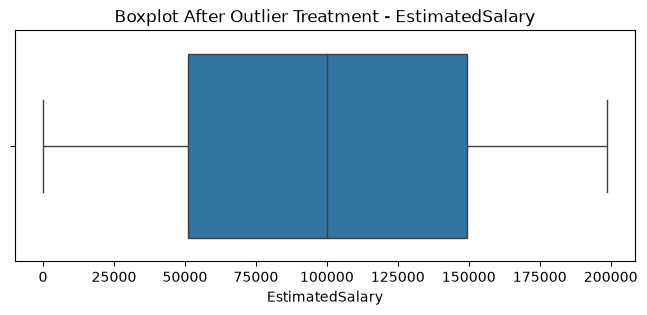

In [24]:
# Check boxplot again
for column in numeric_columns:

    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot After Outlier Treatment - {column}")
    plt.show()


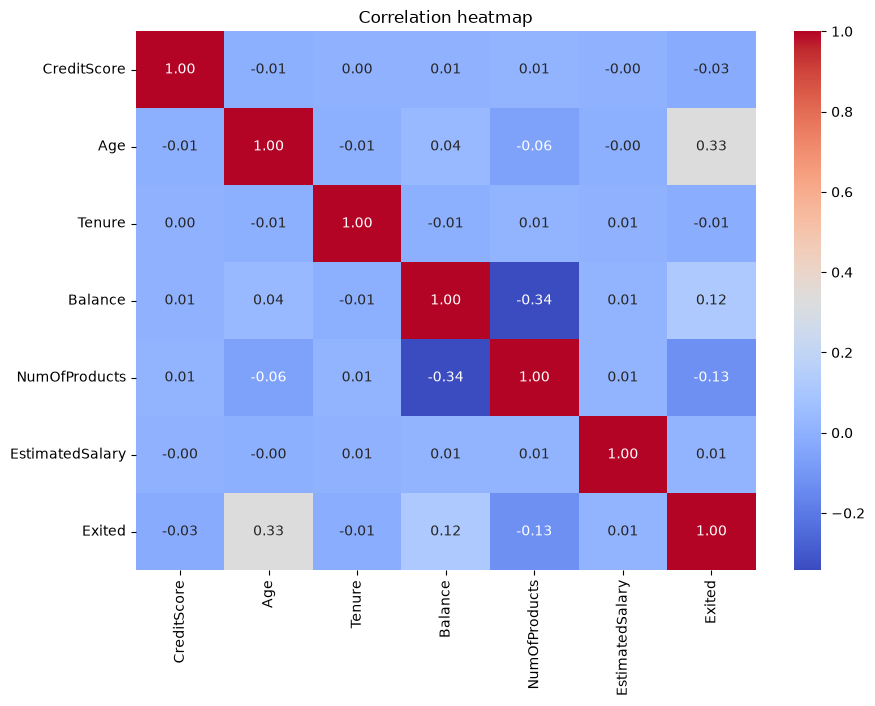

In [25]:
# correlation heatmap

plt.figure(figsize=(10,7))
correlation = df[numeric_columns + ["Exited"]].corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

In [26]:
# Removing unnecessary columns

df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df_model.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1.0,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1.0,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,2.5,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2.0,0,0,93826.63,0
4,785,Spain,Female,43,2,125510.82,1.0,1,1,79084.10,0


In [27]:
# encoding categorical variables

geography_encoder = LabelEncoder()
gender_encoder = LabelEncoder()

df_model["Geography"] = geography_encoder.fit_transform(df_model["Geography"])
df_model["Gender"] = gender_encoder.fit_transform(df_model["Gender"])


In [28]:
print("Geography mapping:")

for category, value in zip(
    geography_encoder.classes_,
    geography_encoder.transform(geography_encoder.classes_)
):
    print(category, "=", value)

Geography mapping:
France = 0
Germany = 1
Spain = 2


In [29]:
print("\nGender Mapping:")

for category, value in zip(
    gender_encoder.classes_,
    gender_encoder.transform(
        gender_encoder.classes_
    )
):
    print(category, "=", value)


Gender Mapping:
Female = 0
Male = 1


In [30]:
# separate X and y

X = df_model.drop("Exited", axis=1)
y = df_model["Exited"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 10)
Target shape: (10000,)


In [31]:
# train-test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training shape:", X_train.shape)
print("testing shape:", y_test.shape)

Training shape: (8000, 10)
testing shape: (2000,)


In [32]:
# Feature scaling

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (8000, 10)
Scaled testing shape: (2000, 10)


In [33]:
# ANN building

model = Sequential([
    Dense(128, activation='relu', input_shape = (X_train_scaled.shape[1],)), Dropout(0.30),
    Dense(32, activation='relu'), Dropout(0.2),
    Dense(1, activation='sigmoid')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,569 (21.75 KB)

 Trainable params: 5,569 (21.75 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
# compile ANN
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [35]:
# early stopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [36]:
# Model checkpoint

checkpoint = ModelCheckpoint(
    "best_basic_ann.keras", 
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [37]:
# Train basic ANN

history = model.fit(
    X_train_scaled, y_train,
    validation_split = 0.2, epochs=100,
    batch_size=32, 
    callbacks= [early_stopping, checkpoint],
    verbose=1
)

Epoch 1/100
188/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8024 - loss: 0.4591
Epoch 1: val_loss improved from None to 0.42195, saving model to best_basic_ann.keras

Epoch 1: finished saving model to best_basic_ann.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8014 - loss: 0.4601 - val_accuracy: 0.8425 - val_loss: 0.4219
Epoch 2/100
174/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8173 - loss: 0.4242
Epoch 2: val_loss improved from 0.42195 to 0.40895, saving model to best_basic_ann.keras

Epoch 2: finished saving model to best_basic_ann.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8173 - loss: 0.4243 - val_accuracy: 0.8469 - val_loss: 0.4090
Epoch 3/100
186/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8290 - loss: 0.4103  
Epoch 3: val_loss improved from 0.40895 to 0.39689, saving model to best_basic_ann.keras

Epoch 3: finished saving model to best_basic_ann.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8277 - loss: 0.4

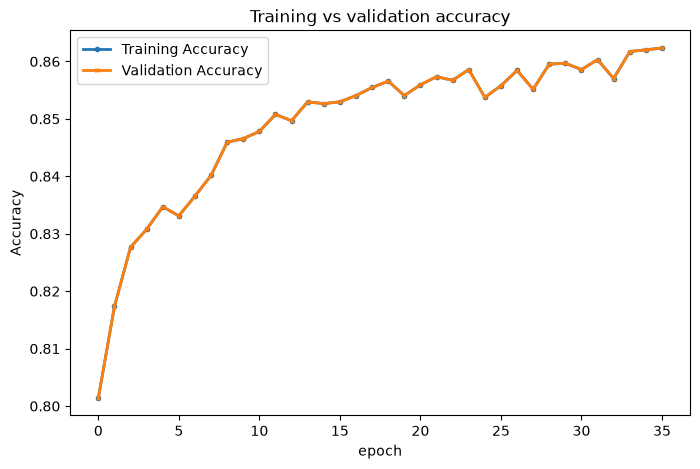

In [38]:
# plot training accuracy

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy", marker='o', markersize=3, linewidth=2)

plt.plot(history.history["accuracy"], label="Validation Accuracy", marker='x', markersize=3, linewidth=2)
plt.title("Training vs validation accuracy")
plt.xlabel("epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

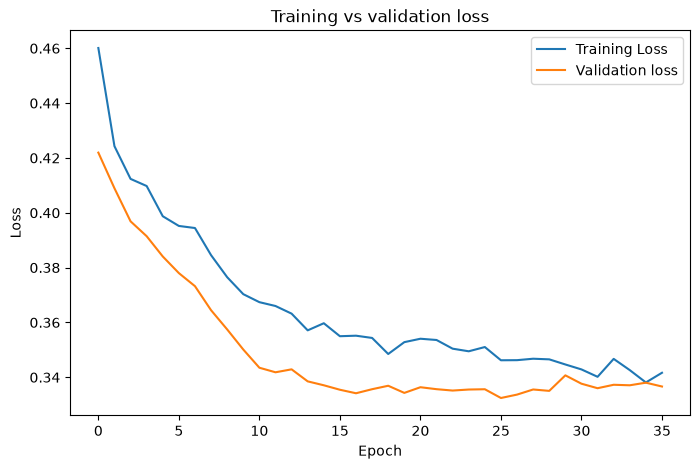

In [39]:
# plot training loss

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Training vs validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()




In [40]:
# Evaluate basic ANN
basic_loss, basic_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Basic ANN test loss:", basic_loss)
print("basic ANN test accuracy:", basic_accuracy)

Basic ANN test loss: 0.3511117100715637
basic ANN test accuracy: 0.8510000109672546


In [41]:
# basic ANN prediction

basic_probability = model.predict(X_test_scaled)
basic_prediction = (basic_probability>=0.5).astype(int).flatten()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 928us/step


In [42]:
# Classification report

print(classification_report(y_test, basic_prediction))

              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1593
           1       0.73      0.42      0.53       407

    accuracy                           0.85      2000
   macro avg       0.80      0.69      0.72      2000
weighted avg       0.84      0.85      0.83      2000



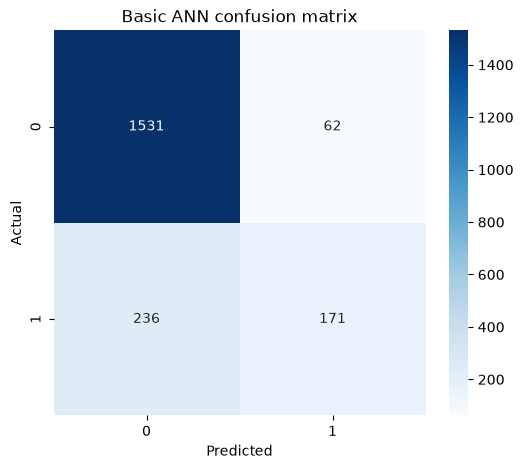

In [43]:
# confusion matrix

cm = confusion_matrix(y_test, basic_prediction)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Basic ANN confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [44]:
# basic ANN roc-auc

basic_auc = roc_auc_score(y_test, basic_probability)

print("Basic ANN ROC-AUC:", basic_auc)

Basic ANN ROC-AUC: 0.8472370675760507


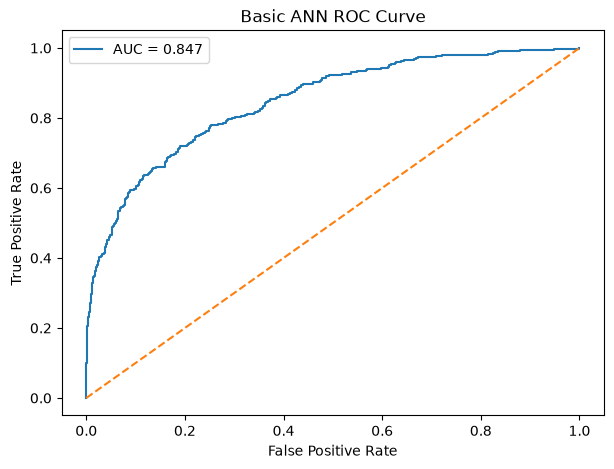

In [45]:
# ROC- curve

fpr, tpr, thresholds = roc_curve(y_test, basic_probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {basic_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Basic ANN ROC Curve")
plt.legend()
plt.show()

In [46]:
# Hyperparameter tuning

def build_tuned_model(hp):

    model = Sequential()

    # Input layer
    model.add(
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        )
    )

    # Number of hidden layers
    num_layers = hp.Int(
        "num_layers",
        min_value=2,
        max_value=4,
        step=1
    )

    # Hidden layers
    for i in range(num_layers):

        units = hp.Int(
            f"units_{i}",
            min_value=32,
            max_value=128,
            step=32
        )

        activation = hp.Choice(
            f"activation_{i}",
            values=["relu", "tanh"]
        )

        model.add(
            Dense(
                units=units,
                activation=activation
            )
        )

        # Dropout after every hidden layer
        dropout_rate = hp.Float(
            f"dropout_{i}",
            min_value=0.0,
            max_value=0.5,
            step=0.1
        )

        model.add(
            Dropout(dropout_rate)
        )

    # Output layer
    model.add(
        Dense(
            1,
            activation="sigmoid"
        )
    )

    # Optimizer
    optimizer_name = hp.Choice(
        "optimizer",
        values=["adam", "rmsprop", "sgd"]
    )

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005, 0.0001]
    )

    if optimizer_name == "adam":

        optimizer = keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    elif optimizer_name == "rmsprop":

        optimizer = keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    else:

        optimizer = keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    # Compile
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [47]:
# create kerastuner

tuner = kt.RandomSearch(
    build_tuned_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="keras_tuner_results",
    project_name="bank_churn_final",
    overwrite=True,
    seed=42
)

In [48]:
# display search space


tuner.search_space_summary()

Search space summary
Default search space size: 9
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 2, 'max_value': 4, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
activation_0 (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
dropout_0 (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
activation_1 (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
dropout_1 (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
optimizer (Choice)
{'default': 'adam', 'conditions': [], 'values': ['adam', 'rmsprop', 'sgd'], 'ordered': False}
learning_rate (Choice

In [49]:
tuner.search(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Trial 10 Complete [00h 00m 19s]
val_accuracy: 0.871874988079071

Best val_accuracy So Far: 0.8731250166893005
Total elapsed time: 00h 03m 17s


In [50]:
# get best hyperparameters

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Number of Hidden Layers:", best_hps.get("num_layers"))
print("Best Optimizer:", best_hps.get("optimizer"))
print("Best Learning Rate:", best_hps.get("learning_rate"))

# display layer parameters

print("Best Number of Hidden Layers:", best_hps.get("num_layers"))
print("Best Optimizer:", best_hps.get("optimizer"))
print("Best Learning Rate:", best_hps.get("learning_rate"))

Best Number of Hidden Layers: 2
Best Optimizer: rmsprop
Best Learning Rate: 0.001
Best Number of Hidden Layers: 2
Best Optimizer: rmsprop
Best Learning Rate: 0.001


In [51]:
# build best tuned model

best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,569 (21.75 KB)

 Trainable params: 5,569 (21.75 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
# model checkpoint for tuned model

tuned_checkpoint = ModelCheckpoint(
    "best_basic_ann.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [53]:
# Early stopping for tuned model

tuned_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [54]:
# Trained tuned model

tuned_history = best_model.fit(
    X_train_scaled, y_train,
    validation_split = 0.20,
    epochs=100,
    batch_size=32,
    callbacks = [tuned_checkpoint, tuned_early_stopping],
    verbose=1
)

Epoch 1/100
144/200 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.7893 - loss: 0.4662
Epoch 1: val_loss improved from None to 0.42247, saving model to best_basic_ann.keras

Epoch 1: finished saving model to best_basic_ann.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7930 - loss: 0.4625 - val_accuracy: 0.8269 - val_loss: 0.4225
Epoch 2/100
196/200 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - accuracy: 0.8123 - loss: 0.4298
Epoch 2: val_loss improved from 0.42247 to 0.41233, saving model to best_basic_ann.keras

Epoch 2: finished saving model to best_basic_ann.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8128 - loss: 0.4299 - val_accuracy: 0.8338 - val_loss: 0.4123
Epoch 3/100
174/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8184 - loss: 0.4207
Epoch 3: val_loss improved from 0.41233 to 0.40542, saving model to best_basic_ann.keras

Epoch 3: finished saving model to best_basic_ann.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8188 - loss: 0

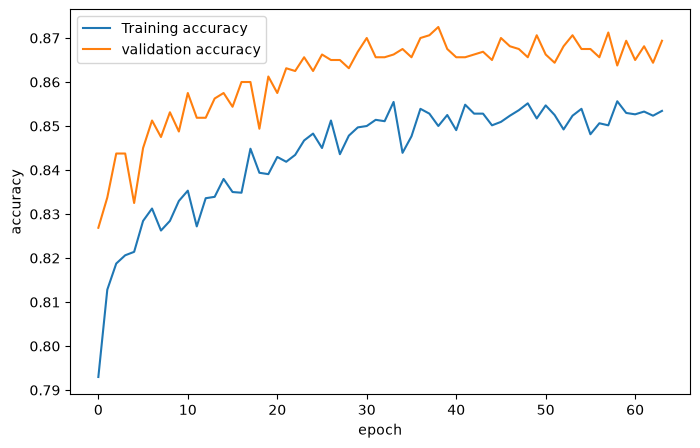

In [55]:
# Tuned model accuracy graph

plt.figure(figsize=(8,5))
plt.plot(tuned_history.history["accuracy"], label="Training accuracy")

plt.plot(tuned_history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

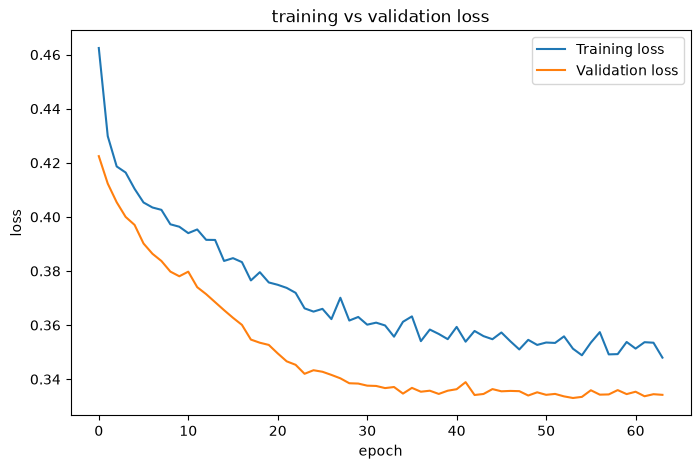

In [56]:
# tuned model loss graph

plt.figure(figsize=(8,5))
plt.plot(tuned_history.history["loss"], label="Training loss")

plt.plot(tuned_history.history["val_loss"], label="Validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("training vs validation loss")
plt.legend()
plt.show()

In [57]:
# evaluate tuned model

tuned_loss, tuned_accuracy = best_model.evaluate(
    X_test_scaled, y_test,
    verbose=0
)
print("tuned ANN test loss:", tuned_loss)
print("tuned ANN test accuracy:", tuned_accuracy)

tuned ANN test loss: 0.3395226001739502
tuned ANN test accuracy: 0.8610000014305115


In [58]:
# tuned model prediction

tuned_probability = best_model.predict(X_test_scaled)
tuned_prediction = (tuned_probability>=0.5).astype(int).flatten()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [59]:
# tuned classification report

print(classification_report(y_test, tuned_prediction))

              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.78      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000



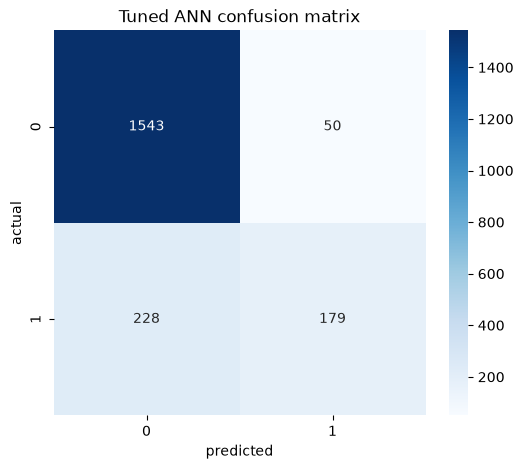

In [60]:
# tuned confusion matrix

cm_tuned = confusion_matrix(y_test, tuned_prediction)

plt.figure(figsize=(6,5))
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned ANN confusion matrix")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

In [61]:
# tuned roc-auc

tuned_auc = roc_auc_score(y_test, tuned_probability)
print("Tuned ANN roc-auc:", tuned_auc)

Tuned ANN roc-auc: 0.8619744551947941


In [62]:
# compare basic ANN and tuned ANN

results = pd.DataFrame({
    "Model": ["Basic ANN", "Tuned ANN"],
    "Accuracy": [basic_accuracy, tuned_accuracy],
    'ROC-AUC': [basic_auc, tuned_auc]
})
results

,Model,Accuracy,ROC-AUC
0,Basic ANN,0.851,0.847237
1,Tuned ANN,0.861,0.861974


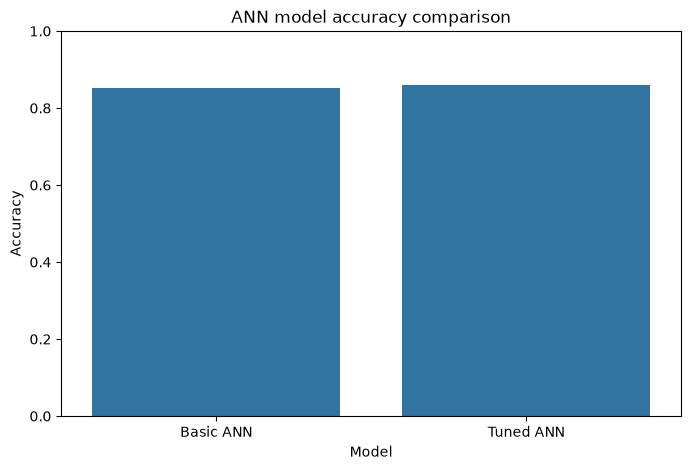

In [63]:
# ACcuracy comparison graph

plt.figure(figsize=(8,5))
sns.barplot(data=results, x="Model", y="Accuracy")
plt.title("ANN model accuracy comparison")
plt.ylim(0,1)
plt.show()

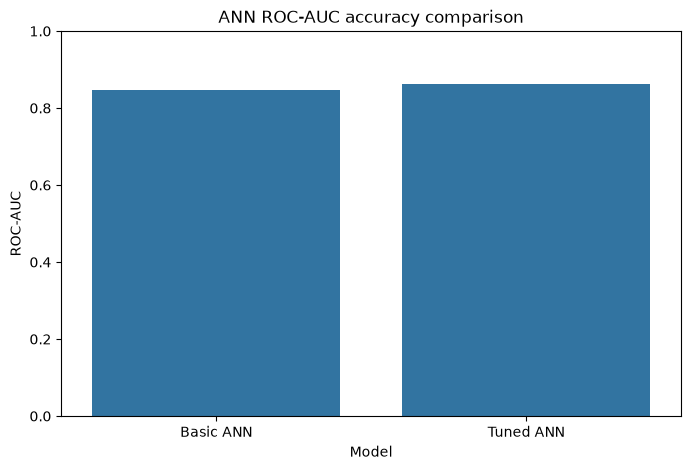

In [64]:
# ROC-AUC Comparison

plt.figure(figsize=(8,5))
sns.barplot(data=results, x="Model", y="ROC-AUC")
plt.title("ANN ROC-AUC accuracy comparison")
plt.ylim(0,1)
plt.show()

In [65]:
#Print final results

print("=" *60)
print("Bank customer churn - model comparison")
print("=" * 60)
print(f"Basic ANN Accuracy: {basic_accuracy:.4f}")
print(f"Tuned ANN Accuracy: {tuned_accuracy}")
print(f"Basic ANN ROC-AUC: {basic_auc:.4f}")
print(f"Tuned ANN ROC-AUC: {tuned_auc:.4f}")
print("=" * 60)

Bank customer churn - model comparison
Basic ANN Accuracy: 0.8510
Tuned ANN Accuracy: 0.8610000014305115
Basic ANN ROC-AUC: 0.8472
Tuned ANN ROC-AUC: 0.8620


In [66]:
# save final model

best_model.save("final_bank_churn_ann_model.keras")
print("Final ANN model saved successfully")

Final ANN model saved successfully


In [67]:
# save label encoder and scaler

import joblib

joblib.dump(geography_encoder, "geography_encoder.pkl")
joblib.dump(gender_encoder, "gender_encoder.pkl")
joblib.dump(scaler, "feature_scaler.pkl")
print("Encoders and scaler saved successfully")

Encoders and scaler saved successfully


In [ ]:
# predict churn for a new customer

new_customer = pd.DataFrame({
    "CreditScore": [650],
    "Geography": ["France"],
    "Gender": ["Male"],
    "Age": [40],
    "Tenure": [5],
    "Balance": [75000],
    "NumOfProducts": [2],
    "HasCrCard": [1],
    "IsActiveMember": [1],
    "EstimatedSalary": [100000]
})

In [69]:
new_customer["Geography"] = geography_encoder.transform(
    [new_customer["Geography"]]
)[0]

new_customer["Gender"] = gender_encoder.transform(
    [new_customer["Gender"]]
)[0]

print(new_customer)

   CreditScore  Geography  Gender  Age  Tenure  Balance  NumOfProducts  \
0          650          0       1   40       5    75000              2   

   HasCrCard  IsActiveMember  EstimatedSalary  
0          1               1           100000  


In [70]:
print("Current Geography:", new_customer["Geography"])
print("Current Gender:", new_customer["Gender"])

Current Geography: 0    0
Name: Geography, dtype: int64
Current Gender: 0    1
Name: Gender, dtype: int64


In [71]:
# Create a fresh new customer using ORIGINAL category names

new_customer = pd.DataFrame({
    "CreditScore": [650],
    "Geography": ["France"],
    "Gender": ["Female"],
    "Age": [40],
    "Tenure": [5],
    "Balance": [60000],
    "NumOfProducts": [2],
    "HasCrCard": [1],
    "IsActiveMember": [1],
    "EstimatedSalary": [50000]
})

print(new_customer)

   CreditScore Geography  Gender  Age  Tenure  Balance  NumOfProducts  \
0          650    France  Female   40       5    60000              2   

   HasCrCard  IsActiveMember  EstimatedSalary  
0          1               1            50000  


In [ ]:
# encode new customer

new_customer["Geography"] = geography_encoder.transform(
    new_customer["Geography"]
)

new_customer["Gender"] = gender_encoder.transform(
    new_customer["Gender"]
)

print(new_customer)

   CreditScore  Geography  Gender  Age  Tenure  Balance  NumOfProducts  \
0          650          0       0   40       5    60000              2   

   HasCrCard  IsActiveMember  EstimatedSalary  
0          1               1            50000  


In [73]:
# scale new customer

new_customer_scaled = scaler.transform(new_customer)

In [75]:
# make churn prediction

churn_probability = best_model.predict(new_customer_scaled)[0][0]
print("Churn probability:", churn_probability)

if churn_probability>=0.5:
    print("Prediction: customer is likely to churn")
else:
    print("Prediction: customer is likely to stay")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Churn probability: 0.0928637
Prediction: customer is likely to stay
